# Cooling profiles along the flow

For each snapshot, trace the native cell nearest the peak dissipation in the
$z=0$ slice through $s\in[-10,10]R_\odot$. Positive $s$ follows the flow;
consecutive visits to the same cell are collapsed. The matching maps are in
[0.1-timescales.ipynb](0.1-timescales.ipynb).

Plot $|u_\mathrm{orb}|$, $u_\mathrm{rad}$, $u_\mathrm{int}$ and the heating
prescriptions in $\mathrm{erg\,cm^{-3}}$:
$$
\dot{E}_\mathrm{diss}(100\,\mathrm{s}),\qquad
2\dot{E}_\mathrm{diss}(100\,\mathrm{s}),\qquad
\int_{-10R_\odot}^{10R_\odot}\frac{\dot{E}_\mathrm{diss}}{|\mathbf v|}\,ds.
$$
The second energy panel shows $\Delta u=u(s)-u(s_\mathrm{first})$ (signed
$u_\mathrm{orb}$); the heating prescriptions remain unchanged.

Sample the projected time scales at the nearest grid column to each particle's
$(x,y)$ and plot $t_c/t_\mathrm{dyn}$, $t_v/t_\mathrm{dyn}$ and
$t_\mathrm{es}/t_\mathrm{dyn}$ together, with a reference at unity:
$$
t_c = \frac{\int \rho\varepsilon_\mathrm{th}\,dz}{\int \alpha_p aT^4c\,dz},
\qquad t_\mathrm{dyn}=\sqrt{\frac{R_*^3}{GM_*}}
$$
$$
\Sigma=\int\rho\,dz,\qquad H=\bar z=\frac{\int\rho|z|\,dz}{\Sigma},
\qquad \bar{v_z}=\frac{\int\rho|v_z|\,dz}{\Sigma},\qquad t_v=\frac{H}{\bar{v_z}}
$$
$$
t_\mathrm{es}=\frac{H\tau}{c},\qquad \tau=\int\alpha_\mathrm{ross}\,dz
$$

Integrate the columns over $z\in[-10r_p,10r_p]$. The thermal emission time
neglects reabsorption; the escape estimate uses $H\tau/c$ without a
light-crossing floor.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import sys

sys.path.insert(0, "/home/hey4/rich_tde/dev")

import dev  # isort: skip
import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from scipy.spatial import cKDTree

import richio

plt.style.use(dev.path)
print("Plotting style loaded through:", dev.__file__)

A_RAD = 4 * u.stefan_boltzmann_constant / u.c
NXY, NZ = 256, 512
WORKERS = 8
Z_HALF_WIDTH_RP = 10
DZ_MIDPLANE = 0.1  # RICH code-length units; target spacing next to z=0.
PROFILE_RES = 801  # Includes s=0; 0.025 Rsun steps across the default 20 Rsun.
PROFILE_FIGSIZE = (9, 4.2)
TIMESCALE_PROFILE_FIGSIZE = (5.5, 4.2)
PROFILE_HALF_LENGTH = 10 * u.Rsun
DISSIPATION_INTERVAL = 100 * u.s


def trace_streamline(position, velocity, seed_index, arc_length):
    """Trace dx/ds = v/|v| in a frozen 3D snapshot with midpoint steps.

    position and velocity are triples of unitful native-cell arrays. arc_length
    is an increasing, unitful signed distance grid containing zero exactly once;
    positive distances follow the velocity and negative distances go upstream.
    Start at the center of seed_index. Keep one record per consecutive cell
    visit: return native cell centers, original indices, signed arc distances
    at closest approach to those centers, and distance traveled in each cell.
    Later returns to a cell remain separate visits. Values are always native.
    The stepping grid is internal; it does not set the plotted particle positions.

    One local tree serves both branches. If R=max(abs(arc_length)), the path is
    within R of the seed cell, so a cell farther than 2R cannot be its nearest
    neighbor. A cube of half-width 2R safely contains all possible neighbors.
    Values are stripped only for the numerical tree and stepping operations.
    """
    length_unit = position[0].units
    velocity_unit = velocity[0].units
    seed = u.unyt_array([axis[seed_index] for axis in position]).in_units(length_unit)
    radius = np.max(np.abs(arc_length))
    selection = np.ones(len(position[0]), dtype=bool)
    for axis, center in zip(position, seed):
        selection &= np.abs(axis - center) <= 2 * radius
    original_indices = np.flatnonzero(selection)
    points = np.column_stack(
        [axis[selection].to_value(length_unit) for axis in position]
    )
    velocities = np.column_stack(
        [axis[selection].to_value(velocity_unit) for axis in velocity]
    )
    tree = cKDTree(points)

    def direction(point):
        _, index = tree.query(point)
        speed = np.linalg.norm(velocities[index])
        if not np.isfinite(speed) or speed == 0:
            raise ValueError(
                "Cannot trace a streamline through zero or nonfinite speed."
            )
        return velocities[index] / speed

    distance = arc_length.to_value(length_unit)
    center_index = np.flatnonzero(distance == 0).item()
    path = np.empty((len(distance), 3))
    path[center_index] = seed.to_value(length_unit)
    for branch in (
        range(center_index + 1, len(distance)),
        range(center_index - 1, -1, -1),
    ):
        previous = center_index
        for index in branch:
            ds = distance[index] - distance[previous]
            midpoint = path[previous] + 0.5 * ds * direction(path[previous])
            path[index] = path[previous] + ds * direction(midpoint)
            previous = index
    _, nearest = tree.query(path)
    sampled_speeds = np.linalg.norm(velocities[nearest], axis=1)
    if not np.all(np.isfinite(sampled_speeds) & (sampled_speeds > 0)):
        raise ValueError("The sampled streamline contains zero or nonfinite speed.")
    # Collapse repeated samples of the same cell, retaining its actual center.
    changes = np.flatnonzero(nearest[1:] != nearest[:-1]) + 1
    starts = np.r_[0, changes]
    stops = np.r_[changes, len(nearest)]
    cells = nearest[starts]
    closest = []
    for start, stop, cell in zip(starts, stops, cells):
        offset = path[start:stop] - points[cell]
        closest.append(start + np.argmin(np.sum(offset**2, axis=1)))

    # Midpoint crossing estimates preserve the full interval and its integral.
    edges = np.r_[
        distance[0],
        0.5 * (distance[changes - 1] + distance[changes]),
        distance[-1],
    ]
    cell_lengths = u.unyt_array(np.diff(edges), length_unit).in_units(arc_length.units)
    return (
        u.unyt_array(points[cells], length_unit),
        original_indices[cells],
        arc_length[closest],
        cell_lengths,
    )

Plotting style loaded through: /home/hey4/rich_tde/dev/dev/__init__.py


## 10^5

Run: 1e5 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 8.399129417106058 day
Snapshot 200, time = 8.392226394376534 day (0.999 t_fb)


Streamline seed cell: 26510781 at [27.5446694  -5.49622165 -0.11193129] Rsun ; positive s follows the 3D velocity
Native particle visits: 100 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 18946175230.675385 erg/cm**3


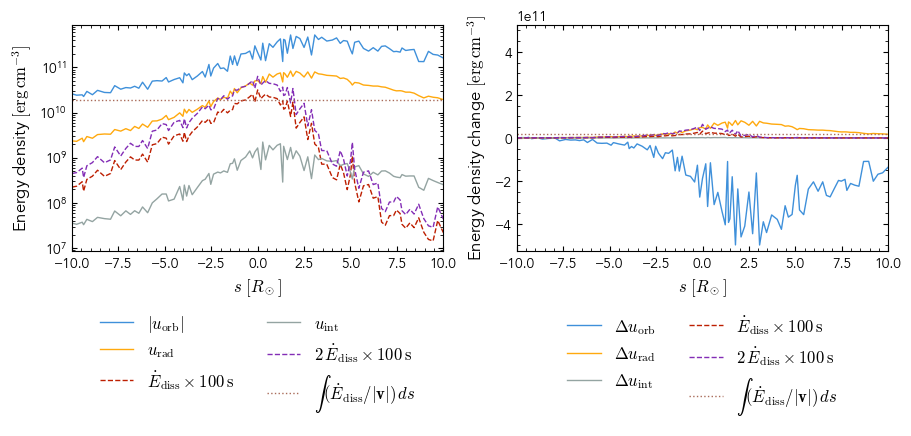

Projected time scales along the flow: nearest grid columns; max XY offset = 0.5375465646739864 Rsun


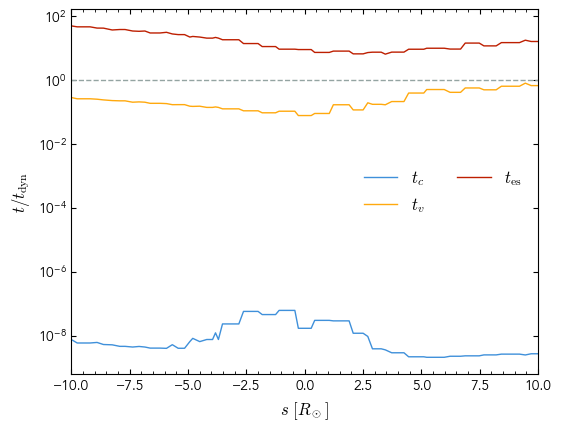

Snapshot 173, time = 5.890262161576989 day (0.701 t_fb)


Streamline seed cell: 27947704 at [20.43658606 -3.08851404  0.120258  ] Rsun ; positive s follows the 3D velocity
Native particle visits: 105 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 1460390278.387491 erg/cm**3


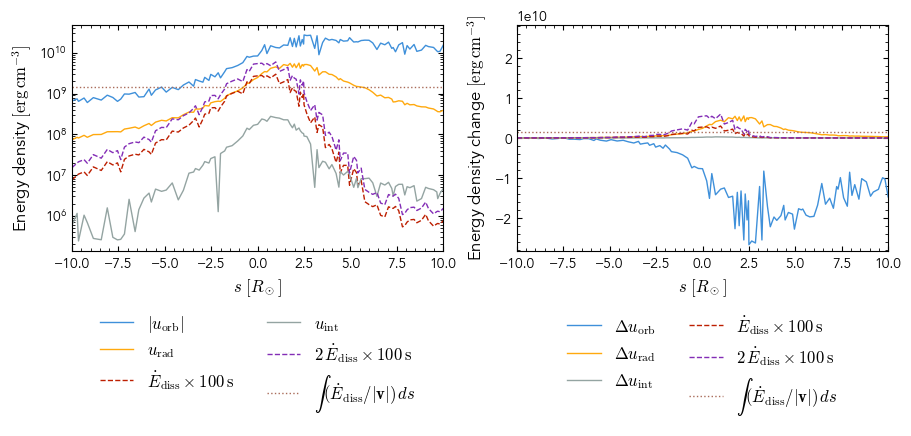

Projected time scales along the flow: nearest grid columns; max XY offset = 0.5387044585679774 Rsun


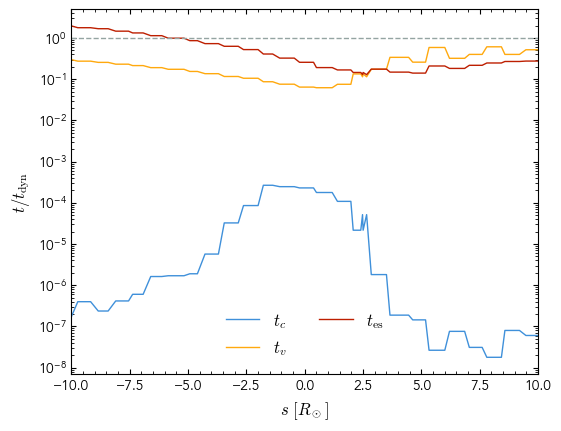

In [2]:
RUN = "1e5"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e5 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

z_half_width = Z_HALF_WIDTH_RP * r_p

XY = 100

TFBS = [0.7, 1.0]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in reversed(SNAPSHOTS):
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    alpha_ross_flat = richio.opacity.rosseland_alpha(snap.T, snap.rho)
    alpha_planck_flat = richio.opacity.planck_alpha(snap.T, snap.rho)

    box = [-XY, -XY, -z_half_width, XY, XY, z_half_width]
    i, xspace, yspace, zspace = snap.to_3dgrid(
        res=(NXY, NXY, NZ),
        box_size=box,
        workers=WORKERS,
        endpoint=False,
        spacing=("linear", "linear", "sinh"),
        central_spacing=(None, None, DZ_MIDPLANE),
    )

    xspace = xspace.in_units("Rsun")
    yspace = yspace.in_units("Rsun")

    s = np.s_[:-1, :-1, :-1]
    rho = snap.rho[i][s]
    T = snap.T[i][s]
    vz = snap.vz[i][s]
    sie = snap.sie[i][s]
    alpha_ross = alpha_ross_flat[i][s]
    alpha_planck = alpha_planck_flat[i][s]

    dz = zspace[1:] - zspace[:-1]
    z = np.abs(zspace[:-1])

    surface_density = np.sum(rho * dz, axis=-1)
    zbar = np.sum(rho * z * dz, axis=-1) / surface_density
    vzbar = np.sum(rho * np.abs(vz) * dz, axis=-1) / surface_density
    t_vertical = zbar / vzbar

    t_cool = np.sum(rho * sie * dz, axis=-1) / np.sum(
        alpha_planck * A_RAD * T**4 * u.c * dz, axis=-1
    )

    tau = np.sum(alpha_ross * dz, axis=-1)
    t_escape = zbar * tau / u.c

    # Calculate volumetric energy fields on the native particles first.
    x_flat, y_flat, z_flat = snap.X, snap.Y, snap.Z
    rho_flat = snap.rho
    vx_flat, vy_flat, vz_flat = snap.vx, snap.vy, snap.vz
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)

    # PW potential, continuously matched to the harmonic core at h = 0.6 r_p.
    r_s = 2 * u.G * MBH / u.c**2
    h = 0.6 * r_p * richio.units.lscale
    potential = -u.G * MBH / (np.maximum(radius, h) - r_s)
    inner = radius < h
    potential[inner] += (
        u.G * MBH * (radius[inner] ** 2 - h**2) / (2 * h * (h - r_s) ** 2)
    )
    orbital_energy_flat = rho_flat * (
        0.5 * (vx_flat**2 + vy_flat**2 + vz_flat**2) + potential
    )
    dissipation_flat = snap.dissipation
    internal_energy_flat = rho_flat * snap.sie
    radiation_energy_flat = rho_flat * snap.Erad

    # Slice dissipation at z=0 to choose the streamline seed.
    slice_options = {
        "res": (NXY, NXY),
        "X": x_flat,
        "Y": y_flat,
        "Z": z_flat,
        "plane": "xy",
        "slice_coord": 0,
        "box_size": [-XY, -XY, XY, XY],
        "workers": WORKERS,
    }
    dissipation, x_slice, y_slice = snap.slice(dissipation_flat, **slice_options)

    x_slice = x_slice.in_units("Rsun")
    y_slice = y_slice.in_units("Rsun")
    dissipation = dissipation.in_units("erg/(cm**3*s)")
    # Select the peak among positive heating cells.
    dissipation[dissipation <= 0] = np.nan

    # Find the native cell represented by the maximum of the z=0 map.
    peak_xy = np.unravel_index(np.nanargmax(dissipation), dissipation.shape)
    x_peak, y_peak = x_slice[peak_xy[0]], y_slice[peak_xy[1]]
    midplane = np.abs(z_flat) < snap.volume ** (1 / 3)
    midplane_indices = np.flatnonzero(midplane)
    distance_to_peak = (
        (x_flat[midplane] - x_peak) ** 2
        + (y_flat[midplane] - y_peak) ** 2
        + z_flat[midplane] ** 2
    )
    peak_cell = midplane_indices[np.argmin(distance_to_peak)]
    arc_length = np.linspace(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH, PROFILE_RES)
    stream_positions, stream_indices, stream_s, stream_lengths = trace_streamline(
        (x_flat, y_flat, z_flat),
        (vx_flat, vy_flat, vz_flat),
        peak_cell,
        arc_length,
    )
    print(
        "Streamline seed cell:",
        peak_cell,
        "at",
        stream_positions[np.flatnonzero(stream_s == 0).item()].in_units("Rsun"),
        "; positive s follows the 3D velocity",
    )

    print(
        "Native particle visits:",
        len(stream_indices),
        "from",
        PROFILE_RES,
        "tracing samples",
    )

    stream_xy = stream_positions[:, :2].in_units("Rsun")
    stream_marker = "o" if len(stream_indices) == 1 else None

    fig, (ax, delta_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for color_index, (field, label, linestyle) in enumerate(
        [
            (np.abs(orbital_energy_flat), r"$|u_\mathrm{orb}|$", "-"),
            (radiation_energy_flat, r"$u_\mathrm{rad}$", "-"),
            (
                dissipation_flat * DISSIPATION_INTERVAL,
                r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
                "--",
            ),
            (internal_energy_flat, r"$u_\mathrm{int}$", "-"),
            (
                2 * dissipation_flat * DISSIPATION_INTERVAL,
                r"$2\,\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
                "--",
            ),
        ]
    ):
        if field is None:
            print("Radiation profile unavailable (not stored in this run)")
            continue
        energy_profile = field[stream_indices]
        ax.semilogy(
            stream_s,
            energy_profile.in_units("erg/cm**3"),
            nonpositive="mask",
            linestyle=linestyle,
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    # Weight each native-cell heating / speed by the arc length spent in that cell.
    speed_flat = np.sqrt(vx_flat**2 + vy_flat**2 + vz_flat**2)
    dissipation_per_length = (dissipation_flat / speed_flat)[stream_indices]
    integrated_dissipation = np.sum(dissipation_per_length * stream_lengths).in_units(
        "erg/cm**3"
    )
    print(
        "Integral of dissipation / speed over the 20 Rsun streamline:",
        integrated_dissipation,
    )
    ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    ax.set_xlabel(r"$s\ [R_\odot]$")
    ax.set_ylabel(r"Energy density $[\mathrm{erg\,cm^{-3}}]$")
    # Changes from the first retained upstream particle; orbital energy is signed.
    for field, label, color_index in [
        (orbital_energy_flat, r"$\Delta u_\mathrm{orb}$", 0),
        (radiation_energy_flat, r"$\Delta u_\mathrm{rad}$", 1),
        (internal_energy_flat, r"$\Delta u_\mathrm{int}$", 3),
    ]:
        if field is None:
            continue
        energy_profile = field[stream_indices].in_units("erg/cm**3")
        delta_ax.plot(
            stream_s,
            energy_profile - energy_profile[0],
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    # These heating prescriptions already represent energy-density changes.
    heating_profile = (
        dissipation_flat[stream_indices] * DISSIPATION_INTERVAL
    ).in_units("erg/cm**3")
    for factor, label, color_index in [
        (1, r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$", 2),
        (2, r"$2\,\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$", 4),
    ]:
        delta_ax.plot(
            stream_s,
            factor * heating_profile,
            linestyle="--",
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    for profile_ax in (ax, delta_ax):
        profile_ax.axhline(
            integrated_dissipation,
            color=profile_colors[5],
            linestyle=":",
            label=r"$\int (\dot{E}_\mathrm{diss}/|\mathbf{v}|)\,ds$",
        )
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    delta_limit = max(abs(limit) for limit in delta_ax.get_ylim())
    delta_ax.set_ylim(-delta_limit, delta_limit)
    delta_ax.set_xlabel(r"$s\ [R_\odot]$")
    delta_ax.set_ylabel(r"Energy density change $[\mathrm{erg\,cm^{-3}}]$")
    plt.show()
    plt.close(fig)

    # Sample the existing projected columns nearest each native particle's XY.
    # Column samples are at xspace[:-1], yspace[:-1].
    pixel_x = np.abs(stream_xy[:, 0, None] - xspace[None, :-1]).argmin(axis=1)
    pixel_y = np.abs(stream_xy[:, 1, None] - yspace[None, :-1]).argmin(axis=1)
    pixel_offset = np.sqrt(
        (stream_xy[:, 0] - xspace[pixel_x]) ** 2
        + (stream_xy[:, 1] - yspace[pixel_y]) ** 2
    )
    print(
        "Projected time scales along the flow: nearest grid columns; max XY offset =",
        pixel_offset.max(),
    )
    fig, timescale_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    for field, label in [
        (t_cool / t_dyn, r"$t_c$"),
        (t_vertical / t_dyn, r"$t_v$"),
        (t_escape / t_dyn, r"$t_\mathrm{es}$"),
    ]:
        # Keep repeated pixel matches so the profile retains the particle ordering.
        timescale_ax.semilogy(
            stream_s,
            field[pixel_x, pixel_y],
            nonpositive="mask",
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    timescale_ax.axhline(
        1,
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][3],
        linestyle="--",
    )
    timescale_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    timescale_ax.set_xlabel(r"$s\ [R_\odot]$")
    timescale_ax.set_ylabel(r"$t/t_\mathrm{dyn}$")
    timescale_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)

## 10^4

Run: 1e4 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 2.656037932057755 day
Snapshot 151, time = [5.77629162] day (2.175 t_fb)


Streamline seed cell: 45918972 at [7.34646367e+00 6.53119324e-03 8.96453666e-03] Rsun ; positive s follows the 3D velocity
Native particle visits: 239 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 149252089907.25153 erg/cm**3


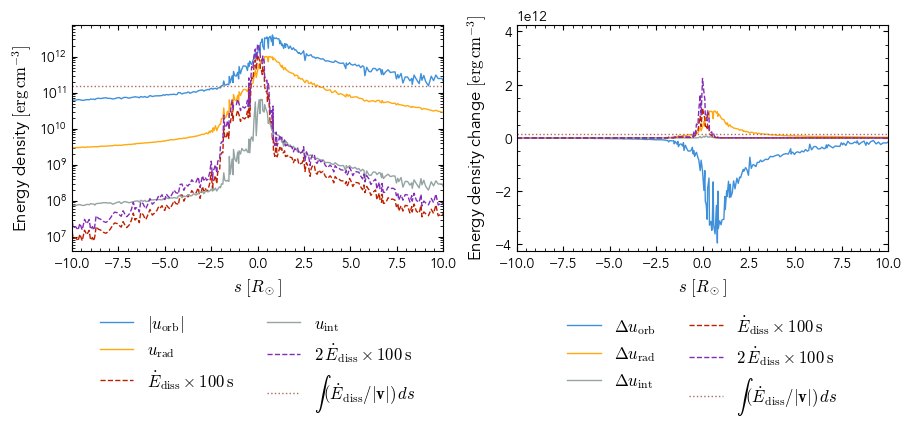

Projected time scales along the flow: nearest grid columns; max XY offset = 0.1636709357989021 Rsun


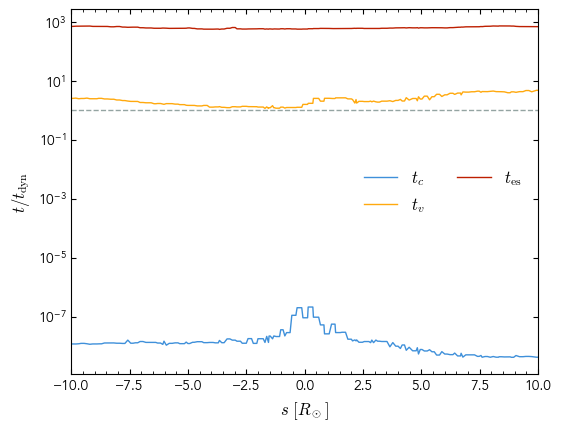

Snapshot 108, time = [3.96398148] day (1.492 t_fb)


Streamline seed cell: 35026811 at [ 9.17365471e+00 -6.81092857e-01 -8.56769517e-03] Rsun ; positive s follows the 3D velocity
Native particle visits: 258 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 132334099794.58977 erg/cm**3


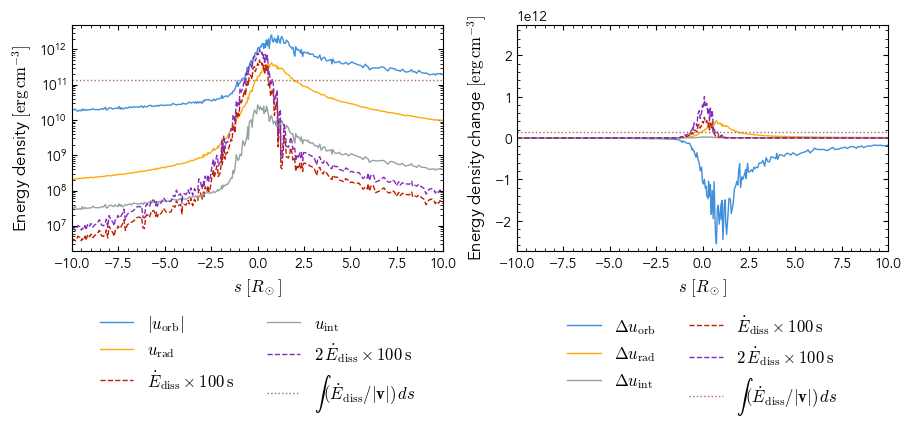

Projected time scales along the flow: nearest grid columns; max XY offset = 0.15389084185663246 Rsun


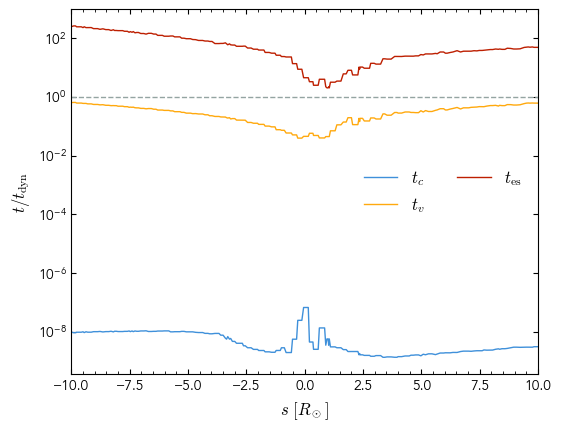

Snapshot 77, time = [2.65338265] day (0.999 t_fb)


Streamline seed cell: 21685525 at [ 9.45924060e+00 -1.86779188e+00 -2.03939956e-03] Rsun ; positive s follows the 3D velocity
Native particle visits: 221 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 11736803943.787188 erg/cm**3


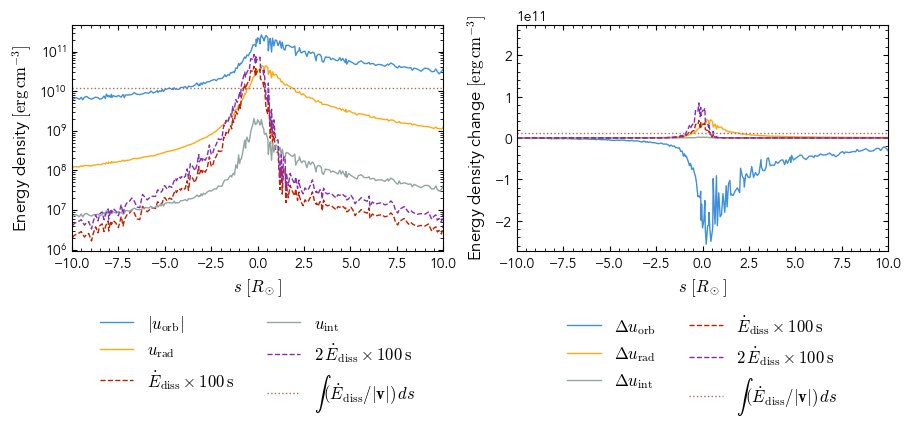

Projected time scales along the flow: nearest grid columns; max XY offset = 0.1634472528342372 Rsun


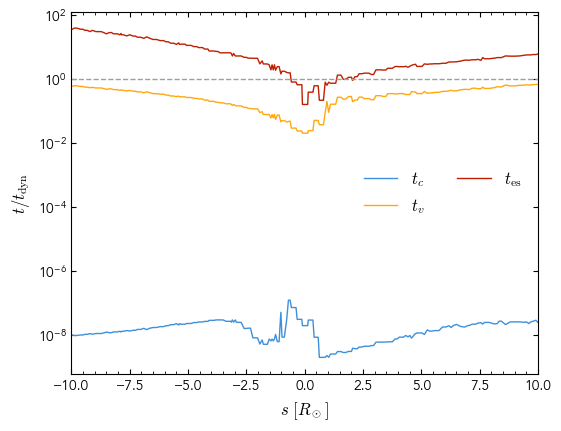

Snapshot 62, time = [1.86088432] day (0.701 t_fb)


Streamline seed cell: 45060881 at [ 9.46025009 -0.93808815  0.02142294] Rsun ; positive s follows the 3D velocity
Native particle visits: 219 from 801 tracing samples


Integral of dissipation / speed over the 20 Rsun streamline: 2605999738.2359786 erg/cm**3


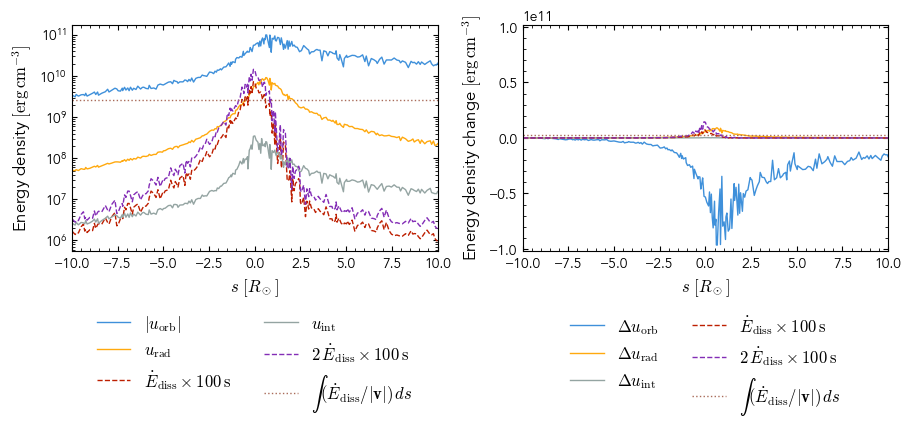

Projected time scales along the flow: nearest grid columns; max XY offset = 0.15458209470730105 Rsun


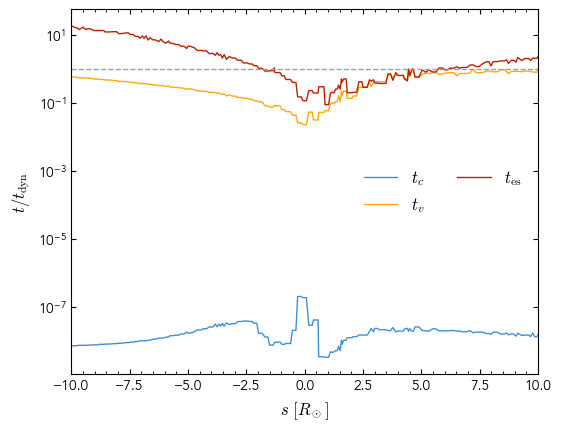

In [4]:
RUN = "1e4"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e4 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

z_half_width = Z_HALF_WIDTH_RP * r_p

XY = 30

TFBS = [0.7, 1.0, 1.5, 2.2]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in reversed(SNAPSHOTS):
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    alpha_ross_flat = richio.opacity.rosseland_alpha(snap.T, snap.rho)
    alpha_planck_flat = richio.opacity.planck_alpha(snap.T, snap.rho)

    box = [-XY, -XY, -z_half_width, XY, XY, z_half_width]
    i, xspace, yspace, zspace = snap.to_3dgrid(
        res=(NXY, NXY, NZ),
        box_size=box,
        workers=WORKERS,
        endpoint=False,
        spacing=("linear", "linear", "sinh"),
        central_spacing=(None, None, DZ_MIDPLANE),
    )

    xspace = xspace.in_units("Rsun")
    yspace = yspace.in_units("Rsun")

    s = np.s_[:-1, :-1, :-1]
    rho = snap.rho[i][s]
    T = snap.T[i][s]
    vz = snap.vz[i][s]
    sie = snap.sie[i][s]
    alpha_ross = alpha_ross_flat[i][s]
    alpha_planck = alpha_planck_flat[i][s]

    dz = zspace[1:] - zspace[:-1]
    z = np.abs(zspace[:-1])

    surface_density = np.sum(rho * dz, axis=-1)
    zbar = np.sum(rho * z * dz, axis=-1) / surface_density
    vzbar = np.sum(rho * np.abs(vz) * dz, axis=-1) / surface_density
    t_vertical = zbar / vzbar

    t_cool = np.sum(rho * sie * dz, axis=-1) / np.sum(
        alpha_planck * A_RAD * T**4 * u.c * dz, axis=-1
    )

    tau = np.sum(alpha_ross * dz, axis=-1)
    t_escape = zbar * tau / u.c

    # Calculate volumetric energy fields on the native particles first.
    x_flat, y_flat, z_flat = snap.X, snap.Y, snap.Z
    rho_flat = snap.rho
    vx_flat, vy_flat, vz_flat = snap.vx, snap.vy, snap.vz
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)

    # PW potential, continuously matched to the harmonic core at h = 0.6 r_p.
    r_s = 2 * u.G * MBH / u.c**2
    h = 0.6 * r_p * richio.units.lscale
    potential = -u.G * MBH / (np.maximum(radius, h) - r_s)
    inner = radius < h
    potential[inner] += (
        u.G * MBH * (radius[inner] ** 2 - h**2) / (2 * h * (h - r_s) ** 2)
    )
    orbital_energy_flat = rho_flat * (
        0.5 * (vx_flat**2 + vy_flat**2 + vz_flat**2) + potential
    )
    dissipation_flat = snap.dissipation
    internal_energy_flat = rho_flat * snap.sie
    radiation_energy_flat = rho_flat * snap.Erad

    # Slice dissipation at z=0 to choose the streamline seed.
    slice_options = {
        "res": (NXY, NXY),
        "X": x_flat,
        "Y": y_flat,
        "Z": z_flat,
        "plane": "xy",
        "slice_coord": 0,
        "box_size": [-XY, -XY, XY, XY],
        "workers": WORKERS,
    }
    dissipation, x_slice, y_slice = snap.slice(dissipation_flat, **slice_options)

    x_slice = x_slice.in_units("Rsun")
    y_slice = y_slice.in_units("Rsun")
    dissipation = dissipation.in_units("erg/(cm**3*s)")
    # Select the peak among positive heating cells.
    dissipation[dissipation <= 0] = np.nan

    # Find the native cell represented by the maximum of the z=0 map.
    peak_xy = np.unravel_index(np.nanargmax(dissipation), dissipation.shape)
    x_peak, y_peak = x_slice[peak_xy[0]], y_slice[peak_xy[1]]
    midplane = np.abs(z_flat) < snap.volume ** (1 / 3)
    midplane_indices = np.flatnonzero(midplane)
    distance_to_peak = (
        (x_flat[midplane] - x_peak) ** 2
        + (y_flat[midplane] - y_peak) ** 2
        + z_flat[midplane] ** 2
    )
    peak_cell = midplane_indices[np.argmin(distance_to_peak)]
    arc_length = np.linspace(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH, PROFILE_RES)
    stream_positions, stream_indices, stream_s, stream_lengths = trace_streamline(
        (x_flat, y_flat, z_flat),
        (vx_flat, vy_flat, vz_flat),
        peak_cell,
        arc_length,
    )
    print(
        "Streamline seed cell:",
        peak_cell,
        "at",
        stream_positions[np.flatnonzero(stream_s == 0).item()].in_units("Rsun"),
        "; positive s follows the 3D velocity",
    )

    print(
        "Native particle visits:",
        len(stream_indices),
        "from",
        PROFILE_RES,
        "tracing samples",
    )

    stream_xy = stream_positions[:, :2].in_units("Rsun")
    stream_marker = "o" if len(stream_indices) == 1 else None

    fig, (ax, delta_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for color_index, (field, label, linestyle) in enumerate(
        [
            (np.abs(orbital_energy_flat), r"$|u_\mathrm{orb}|$", "-"),
            (radiation_energy_flat, r"$u_\mathrm{rad}$", "-"),
            (
                dissipation_flat * DISSIPATION_INTERVAL,
                r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
                "--",
            ),
            (internal_energy_flat, r"$u_\mathrm{int}$", "-"),
            (
                2 * dissipation_flat * DISSIPATION_INTERVAL,
                r"$2\,\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
                "--",
            ),
        ]
    ):
        if field is None:
            print("Radiation profile unavailable (not stored in this run)")
            continue
        energy_profile = field[stream_indices]
        ax.semilogy(
            stream_s,
            energy_profile.in_units("erg/cm**3"),
            nonpositive="mask",
            linestyle=linestyle,
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    # Weight each native-cell heating / speed by the arc length spent in that cell.
    speed_flat = np.sqrt(vx_flat**2 + vy_flat**2 + vz_flat**2)
    dissipation_per_length = (dissipation_flat / speed_flat)[stream_indices]
    integrated_dissipation = np.sum(dissipation_per_length * stream_lengths).in_units(
        "erg/cm**3"
    )
    print(
        "Integral of dissipation / speed over the 20 Rsun streamline:",
        integrated_dissipation,
    )
    ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    ax.set_xlabel(r"$s\ [R_\odot]$")
    ax.set_ylabel(r"Energy density $[\mathrm{erg\,cm^{-3}}]$")
    # Changes from the first retained upstream particle; orbital energy is signed.
    for field, label, color_index in [
        (orbital_energy_flat, r"$\Delta u_\mathrm{orb}$", 0),
        (radiation_energy_flat, r"$\Delta u_\mathrm{rad}$", 1),
        (internal_energy_flat, r"$\Delta u_\mathrm{int}$", 3),
    ]:
        if field is None:
            continue
        energy_profile = field[stream_indices].in_units("erg/cm**3")
        delta_ax.plot(
            stream_s,
            energy_profile - energy_profile[0],
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    # These heating prescriptions already represent energy-density changes.
    heating_profile = (
        dissipation_flat[stream_indices] * DISSIPATION_INTERVAL
    ).in_units("erg/cm**3")
    for factor, label, color_index in [
        (1, r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$", 2),
        (2, r"$2\,\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$", 4),
    ]:
        delta_ax.plot(
            stream_s,
            factor * heating_profile,
            linestyle="--",
            color=profile_colors[color_index],
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    for profile_ax in (ax, delta_ax):
        profile_ax.axhline(
            integrated_dissipation,
            color=profile_colors[5],
            linestyle=":",
            label=r"$\int (\dot{E}_\mathrm{diss}/|\mathbf{v}|)\,ds$",
        )
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    delta_limit = max(abs(limit) for limit in delta_ax.get_ylim())
    delta_ax.set_ylim(-delta_limit, delta_limit)
    delta_ax.set_xlabel(r"$s\ [R_\odot]$")
    delta_ax.set_ylabel(r"Energy density change $[\mathrm{erg\,cm^{-3}}]$")
    plt.show()
    plt.close(fig)

    # Sample the existing projected columns nearest each native particle's XY.
    # Column samples are at xspace[:-1], yspace[:-1].
    pixel_x = np.abs(stream_xy[:, 0, None] - xspace[None, :-1]).argmin(axis=1)
    pixel_y = np.abs(stream_xy[:, 1, None] - yspace[None, :-1]).argmin(axis=1)
    pixel_offset = np.sqrt(
        (stream_xy[:, 0] - xspace[pixel_x]) ** 2
        + (stream_xy[:, 1] - yspace[pixel_y]) ** 2
    )
    print(
        "Projected time scales along the flow: nearest grid columns; max XY offset =",
        pixel_offset.max(),
    )
    fig, timescale_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    for field, label in [
        (t_cool / t_dyn, r"$t_c$"),
        (t_vertical / t_dyn, r"$t_v$"),
        (t_escape / t_dyn, r"$t_\mathrm{es}$"),
    ]:
        # Keep repeated pixel matches so the profile retains the particle ordering.
        timescale_ax.semilogy(
            stream_s,
            field[pixel_x, pixel_y],
            nonpositive="mask",
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    timescale_ax.axhline(
        1,
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][3],
        linestyle="--",
    )
    timescale_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    timescale_ax.set_xlabel(r"$s\ [R_\odot]$")
    timescale_ax.set_ylabel(r"$t/t_\mathrm{dyn}$")
    timescale_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)